# ¿Se puede predecir el tipo de una muestra por lo que se le midió?

**Datos.** Senasa (clasificación manual) + MQ nuevas (clasificación automática por texto o reglas).

**Fuera del entrenamiento** (se usan para evaluar):
- muestras de **calibración**: «control de laboratorio» o descripción con calibración, patrón, referencia,
  repetibilidad / reproducibilidad (la descripción se lee en memoria, no se muestra);
- «ensayo» y «pool»;
- las que **declaran algo que no coincide** con la humedad medida (`declarado_vs_medido`; «borde» sí entra);
- humedad + sólidos fuera de 100 ± 1 y las «sin clasificar».

**Variables.** Resultados numéricos (NaN si no se midieron) y qué análisis se pidieron.
**Modelo.** HistGradientBoosting en dos niveles: familia; después subtipo dentro de cada familia (en queso, la
consistencia del CAA). **Validación** cruzada en 5 pliegues agrupada por envío. Con probabilidad < 0,80 la muestra
queda «sin decidir».

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import prediccion_tipo as PT

r = PT.armar(escribir=True)
t = r["datos"]
r["resumen"]

E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\prediccion_tipo.py:131: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['alta humedad' 'alta humedad' 'alta humedad' ... nan nan
 'mediana humedad']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  y.loc[m, "subtipo"] = d.loc[m, col].map(mapa)


E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\prediccion_tipo.py:131: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['baja humedad' 'alta humedad' 'alta humedad' ... 'baja humedad' nan
 'mediana humedad']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  y.loc[m, "subtipo"] = d.loc[m, col].map(mapa)


,concepto,valor
0,muestras totales,30089
1,entrenamiento,27241
2,calibración (fuera del entrenamiento),449
3,calibración por origen,"{'MQ nueva (automática)': 251, 'Senasa (manual..."
4,declarado no coincide (fuera del entrenamiento),209
5,sin clasificar con análisis,1298
6,exactitud de familia en calibración (con famil...,0.651
7,"ídem, solo con prob ≥ 0.8",0.923
8,no coinciden: el subtipo predicho sigue a la h...,0.87


## Métricas fuera de pliegue
Exactitud, F1 macro y, con el umbral, cuántas muestras se deciden y con qué exactitud.

In [2]:
r["metricas"]

,nivel,origen,muestras,exactitud,F1 macro,% con prob ≥ 0.8,exactitud con prob ≥ 0.8
0,familia,todas,27241,0.792,0.621,64.829,0.949
1,familia,MQ nueva (automática),11678,0.801,0.549,61.475,0.934
2,familia,Senasa (manual),15563,0.785,0.637,67.346,0.959
3,subtipo · queso,todas,5382,0.830,0.819,79.283,0.905
4,subtipo · queso,MQ nueva (automática),2033,0.813,0.780,80.521,0.880
5,subtipo · queso,Senasa (manual),3349,0.840,0.839,78.531,0.920
6,subtipo · leche en polvo,todas,4832,0.976,0.964,98.262,0.985
7,subtipo · leche en polvo,MQ nueva (automática),3803,0.977,0.953,98.396,0.984
8,subtipo · leche en polvo,Senasa (manual),1029,0.972,0.972,97.765,0.989
9,subtipo · dulce de leche,todas,3102,0.810,0.809,80.916,0.889


## ¿Las probabilidades son creíbles?
Exactitud observada por rango de probabilidad (familia).

In [3]:
PT.fiabilidad(r["oof_familia"])

,rango_prob,muestras,prob_media,exactitud
0,"[0.0, 0.5)",4092,0.445546,0.358504
1,"[0.5, 0.6)",2374,0.541152,0.581719
2,"[0.6, 0.7)",1412,0.649713,0.587819
3,"[0.7, 0.8)",1703,0.754353,0.660599
4,"[0.8, 0.9)",2365,0.853345,0.798732
5,"[0.9, 0.95)",2043,0.926825,0.869799
6,"[0.95, 1.0)",13252,0.987385,0.988077


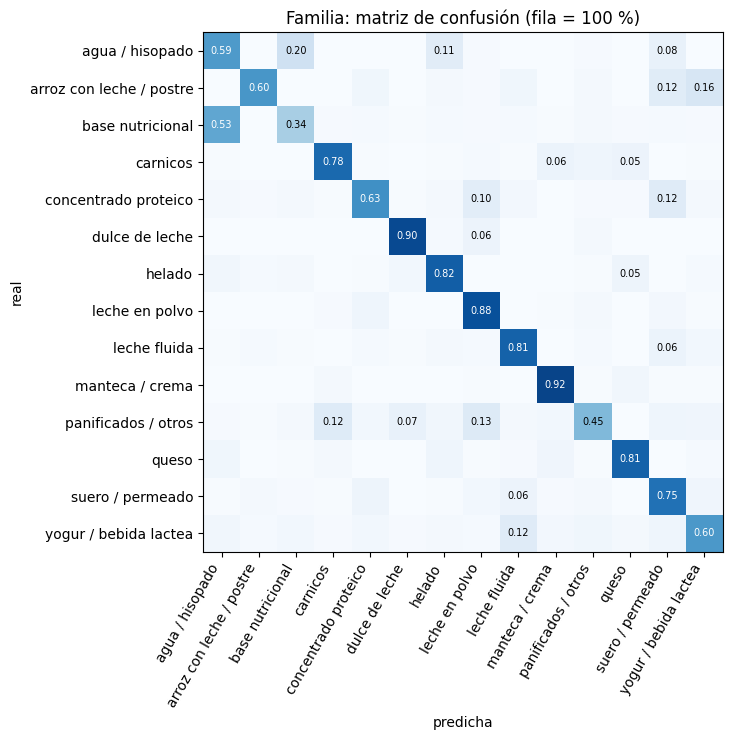

In [4]:
cm = r["confusion"]["familia"]
cmn = cm.div(cm.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=60, ha="right"); ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        if cmn.iat[i, j] >= .05:
            ax.text(j, i, f"{cmn.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if cmn.iat[i, j] > .5 else "k")
ax.set(xlabel="predicha", ylabel="real", title="Familia: matriz de confusión (fila = 100 %)")
plt.tight_layout(); plt.show()

## Muestras de calibración
No entrenaron. Acierto de familia por origen y familia declarada.

In [5]:
cal = r["calibracion"]
cal[cal["desc_familia"].ne(PT.SIN)].groupby(["origen", "desc_familia"]).agg(
    muestras=("acierta_familia", "size"), acierto=("acierta_familia", "mean"), prob_media=("prob_familia", "mean")).round(2)

muestras   acierto  prob_media
origen                desc_familia                                        
MQ nueva (automática) base nutricional            30  0.033333        0.60
                      concentrado proteico         1       0.0        0.54
                      leche en polvo              39   0.74359        0.76
                      leche fluida                30  0.366667        0.58
                      manteca / crema             24  0.541667        0.59
                      queso                       45  0.911111        0.91
                      suero / permeado            15  0.066667        0.57
Senasa (manual)       carnicos                     3       1.0        0.75
                      concentrado proteico         1       0.0        0.63
                      dulce de leche              50      0.64        0.62
                      leche en polvo               1       1.0        0.86
                      leche fluida                86  0.953488        0.67
                      queso                        3       1.0        0.84
                      suero / permeado             7  0.142857        0.50

## Declarado que no coincide con lo medido
En quesos: consistencia declarada, la que corresponde a la humedad medida y la que predice el modelo.

In [6]:
nc = r["no_coinciden"]
q = nc[nc["desc_familia"].eq("queso")]
pd.crosstab([q["subtipo"].rename("declarada"), q["clase_por_humedad"].rename("por humedad")], q["subtipo_pred"].rename("predicha"))

predicha                          alta humedad  baja humedad  bebida láctea  \
declarada       por humedad                                                   
alta humedad    mediana humedad              0             0              0   
baja humedad    mediana humedad              0             1              1   
mediana humedad alta humedad                19             0              0   
                baja humedad                 0             5              0   
                muy alta humedad            19             0              0   

predicha                          mediana humedad  procesado  
declarada       por humedad                                   
alta humedad    mediana humedad                70          6  
baja humedad    mediana humedad                41          0  
mediana humedad alta humedad                    0          1  
                baja humedad                    0          0  
                muy alta humedad                0         11

## «Sin clasificar»: lo que propone el modelo
Solo propuestas; no se cambia ninguna familia.

In [7]:
sc = r["sin_clasificar"]
print(sc["decision"].value_counts().to_string())
sc[sc["decision"].eq("propuesta")]["familia_pred"].value_counts()

decision
sin decidir    818
propuesta      480


familia_pred
carnicos                    182
suero / permeado             72
leche en polvo               61
panificados / otros          39
agua / hisopado              29
queso                        28
manteca / crema              15
yogur / bebida lactea        14
base nutricional             12
dulce de leche               10
leche fluida                  8
concentrado proteico          4
helado                        3
arroz con leche / postre      3
Name: count, dtype: int64

## Datos usados en cada entrenamiento
Cuántas muestras entran en cada modelo de este cuaderno (familia y un modelo de subtipo por familia), cuáles se sacan y por qué,
y cómo se reparte lo que queda. No hay conjunto de validación propio: los hiperparámetros son fijos. La evaluación es la validación
cruzada agrupada por envío; «entrenamiento» y «prueba» son el tamaño medio de cada pliegue. Las muestras de calibración, las que
declaran algo que no coincide y las «sin clasificar» no entrenan: se predicen con el modelo final.

In [8]:
import inspect
import datos_entrenamiento as DE
from datos_clase41 import TOL_HUM_SOL
from sklearn.model_selection import StratifiedGroupKFold

miles = lambda n: f"{int(n):,}".replace(",", ".")
N_PLIEGUES = inspect.signature(PT.validar).parameters["n_folds"].default
CX = PT.columnas_x(t)


def pliegues(objetivo, filtro):
    # Mismas filas y mismos pliegues que PT.validar: devuelve las filas y el tamaño medio de entrenamiento y de prueba.
    base = t[t["entrena"] & filtro & t[objetivo].notna()]
    base = base[base[objetivo].isin(PT._clases_validas(base[objetivo]))]
    cv = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=PT.SEMILLA)
    tam = [(len(a), len(b)) for a, b in cv.split(base[CX], base[objetivo].astype(str), base["Envío"].astype(str))]
    return base, round(np.mean([a for a, _ in tam])), round(np.mean([b for _, b in tam]))


PARTICION = f"validación cruzada de {N_PLIEGUES} pliegues agrupada por envío"
fuera = [("de calibración", t["calibracion"]),
         ("de ensayo, pool u otro tipo que no es producción", ~t["desc_tipo_muestra"].isin(["produccion"])),
         ("sin clasificar o sin familia", t["desc_familia"].eq(PT.SIN) | t["desc_familia"].isna()),
         (f"con humedad + sólidos fuera de 100 ± {TOL_HUM_SOL:g}", t["excluida_hum_sol"]),
         ("con lo declarado distinto de lo medido", t["declarado_no_coincide"]),
         ("sin ningún análisis", t["n_analisis"].eq(0))]
quedan, partes = pd.Series(True, index=t.index), []
for nombre, cond in fuera:
    partes.append(f"{nombre}: {miles((quedan & cond).sum())}")
    quedan &= ~cond
assert quedan.equals(t["entrena"])

base_f, tr_f, te_f = pliegues("desc_familia", pd.Series(True, index=t.index))
assert set(base_f.index) == set(r["oof_familia"].index)
partes.append(f"familias con menos de {PT.MIN_CLASE} muestras: {miles(quedan.sum() - len(base_f))}")
filas = [DE.fila(
    parte="V", modelo="familia: HistGradientBoosting", datos="muestras de Senasa y MQ nuevas",
    disponibles=len(t), usadas=len(base_f), motivo="; ".join(partes), entrenamiento=tr_f, prueba=te_f, particion=PARTICION,
    nota=(f"entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las {miles(len(base_f))} filas; "
          f"con probabilidad menor que {str(PT.UMBRAL_PROB).replace(".", ",")} la muestra queda sin decidir; sin entrenar se predicen "
          f"{miles(len(r['calibracion']))} de calibración, {miles(len(r['no_coinciden']))} con declarado que no coincide y "
          f"{miles(len(r['sin_clasificar']))} sin clasificar con análisis"))]

for fam, oof in r["oof_subtipo"].items():
    de_fam = t["desc_familia"].eq(fam)
    disp = (t["entrena"] & de_fam).sum()
    base_s, tr_s, te_s = pliegues("subtipo", de_fam)
    assert set(base_s.index) == set(oof.index)
    sin_sub = (t["entrena"] & de_fam & t["subtipo"].isna()).sum()
    filas.append(DE.fila(
        parte="V", modelo=f"subtipo · {fam}: HistGradientBoosting", datos=f"muestras de entrenamiento de {fam}",
        disponibles=disp, usadas=len(base_s),
        motivo=(f"sin subtipo declarado o fuera de las clases del mapa: {miles(sin_sub)}; "
                f"subtipos con menos de {PT.MIN_CLASE} muestras: {miles(disp - sin_sub - len(base_s))}"),
        entrenamiento=tr_s, prueba=te_s, particion=PARTICION,
        nota=f"entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las {miles(len(base_s))} filas"))

display(DE.guardar(filas, "prediccion_tipo"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,V,familia: HistGradientBoosting,muestras de Senasa y MQ nuevas,30089,2848,"de calibración: 449; de ensayo, pool u otro ti...",27241,21793,<NA>,5448,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
1,V,subtipo · queso: HistGradientBoosting,muestras de entrenamiento de queso,6659,1277,sin subtipo declarado o fuera de las clases de...,5382,4306,<NA>,1076,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
2,V,subtipo · leche en polvo: HistGradientBoosting,muestras de entrenamiento de leche en polvo,5351,519,sin subtipo declarado o fuera de las clases de...,4832,3866,<NA>,966,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
3,V,subtipo · dulce de leche: HistGradientBoosting,muestras de entrenamiento de dulce de leche,4216,1114,sin subtipo declarado o fuera de las clases de...,3102,2482,<NA>,620,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
4,V,subtipo · suero / permeado: HistGradientBoosting,muestras de entrenamiento de suero / permeado,2171,132,sin subtipo declarado o fuera de las clases de...,2039,1631,<NA>,408,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
5,V,subtipo · leche fluida: HistGradientBoosting,muestras de entrenamiento de leche fluida,2788,839,sin subtipo declarado o fuera de las clases de...,1949,1559,<NA>,390,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
6,V,subtipo · concentrado proteico: HistGradientBo...,muestras de entrenamiento de concentrado proteico,1016,64,sin subtipo declarado o fuera de las clases de...,952,762,<NA>,190,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
7,V,subtipo · manteca / crema: HistGradientBoosting,muestras de entrenamiento de manteca / crema,1305,0,sin subtipo declarado o fuera de las clases de...,1305,1044,<NA>,261,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...
8,V,subtipo · yogur / bebida lactea: HistGradientB...,muestras de entrenamiento de yogur / bebida la...,679,16,sin subtipo declarado o fuera de las clases de...,663,530,<NA>,133,validación cruzada de 5 pliegues agrupada por ...,entrenamiento y prueba son el promedio por pli...


## Lectura
- Con las mediciones solas la **familia** se acierta en ~8 de 10 muestras; con probabilidad ≥ 0,80 se decide ~2/3 de
  las muestras con ~95 % de exactitud. Las probabilidades entre 0,8 y 0,95 son algo optimistas; desde 0,95 son fiables.
- Se confunden familias con composición parecida y pocos análisis: base nutricional con agua / hisopado (se les pide
  poco), concentrado proteico con leche en polvo y suero, queso con helado / manteca.
- Los **subtipos** salen muy bien en leche en polvo (entera / descremada), concentrado proteico, manteca / crema; bien en
  queso (consistencia), DDL y leche fluida; peor en suero / permeado y en yogur de Senasa.
- En los quesos cuya consistencia declarada no coincide, el modelo sigue casi siempre a la **humedad medida**: es
  evidencia de que la consistencia declarada estaba mal, no la medición.
- Las de **calibración** se aciertan peor (son matrices de referencia, a veces con un solo análisis); por eso no deben
  entrar al entrenamiento.
- Archivo: `resultados/excel/prediccion_tipo.xlsx`; modelo: `resultados/modelos/prediccion_tipo.joblib`
  (`PT.predecir(joblib.load(...), X)` con las columnas de `PT._variables`).

In [9]:
assert not (t["entrena"] & t["calibracion"]).any() and not (t["entrena"] & t["declarado_no_coincide"]).any()
assert (PT.R.EXCEL / "prediccion_tipo.xlsx").exists() and PT.SALIDA_MODELO.exists()
for k in ["calibracion", "no_coinciden", "sin_clasificar"]:
    assert "Descripción" not in r[k].columns
    assert r[k]["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$").all()
print("Verificación: todo en orden.")

Verificación: todo en orden.


## La aplicación, desde el cuaderno
La celda siguiente escribe `app_prediccion.py` (dos pestañas: días de espera para deslactosar una UAT y tipo de
muestra según lo medido). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_prediccion.py`.

In [10]:
%%writefile app_prediccion.py
# Trabajo Senasa + MQ · aplicación Streamlit con los dos modelos predictivos
# 1) Cuántos días esperar para que una leche UAT baje de 0,1 g/100 g de lactosa (src/deslactosado_uat.py).
# 2) Tipo de muestra (familia y subtipo) a partir de lo medido (src/prediccion_tipo.py).
# Los modelos los guardan los notebooks prediccion_deslactosado.ipynb y prediccion_tipo.ipynb en resultados/modelos/.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_prediccion.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import deslactosado_uat as D  # noqa: E402
import prediccion_tipo as PT  # noqa: E402

st.set_page_config(page_title="Predicciones Senasa + MQ", layout="centered")
st.title("Predicciones Senasa + MQ")
st.caption("Dos modelos ajustados en los notebooks del trabajo. Cargá los parámetros y la app devuelve el resultado.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


faltan = [p for p in (D.SALIDA_MODELO, PT.SALIDA_MODELO) if not p.exists()]
if faltan:
    st.error("Faltan modelos: " + ", ".join(p.name for p in faltan) + ". Ejecutá los notebooks prediccion_*.ipynb.")
    st.stop()

tab1, tab2 = st.tabs(["Deslactosado UAT", "Tipo de muestra"])

# ------------------------------------------------------------------ 1. deslactosado
with tab1:
    m = cargar(D.SALIDA_MODELO)
    th, boot, umbral = m["theta"], m["boot"], m["umbral"]
    st.subheader("¿Cuántos días esperar?")
    st.write(f"Modelo de primer orden ajustado con {m['n_lotes']} lotes UAT remuestreados de Senasa "
             f"({m['rango_dias'][0]} a {m['rango_dias'][1]} días entre análisis). Umbral de deslactosado: "
             f"**{umbral:.1f} g/100 g**.")
    c1, c2 = st.columns(2)
    l0 = c1.number_input("Lactosa medida (g/100 g)", 0.01, 3.0, 0.60, step=0.01, format="%.2f")
    t_sem = c2.slider("Temperatura media de la semana (°C)", 5.0, 35.0, 18.0, step=0.5)

    if l0 <= umbral:
        st.success(f"Ya está en {umbral:.1f} g/100 g o menos: no hace falta esperar.")
    else:
        dias = float(D.dias_hasta(l0, t_sem, th))
        dd = D.dias_hasta(l0, t_sem, boot.T)
        inf, sup = np.percentile(dd, [2.5, 97.5])
        k1, k2 = st.columns(2)
        k1.metric("Días de espera estimados", f"{dias:.1f}")
        k2.metric("Intervalo 95 % (bootstrap)", f"{inf:.1f} a {sup:.1f}")
        st.write(f"Tasa a esa temperatura: k = {float(D.k_de(th, t_sem)):.3f} por día "
                 f"(la lactosa baja ~{100 * (1 - np.exp(-float(D.k_de(th, t_sem)))):.0f} % por día).")
        if dias > m["rango_dias"][1]:
            st.warning(f"La espera supera los {m['rango_dias'][1]} días observados entre análisis: es una extrapolación.")
        lo, hi = m["rango_t"]
        if not lo - 2 <= t_sem <= hi + 2:
            st.warning(f"Temperatura fuera del rango observado ({lo:.0f} a {hi:.0f} °C): es una extrapolación.")

    st.info("El efecto de la temperatura dentro de los remuestreos no es significativo (el IC incluye cero): "
            "tomá el resultado como orden de magnitud, no como garantía.")

    T = np.linspace(5, 35, 61)
    fig, ax = plt.subplots(figsize=(8, 4))
    for v, col in [(0.3, "#9ecae1"), (0.5, "#4292c6"), (1.0, "#08519c")]:
        ax.plot(T, D.dias_hasta(v, T, th), color=col, lw=1, label=f"L₀ = {v}")
    if l0 > umbral:
        dT = D.dias_hasta(l0, T[:, None], boot.T)
        ax.fill_between(T, *np.percentile(dT, [2.5, 97.5], axis=1), color="#c0392b", alpha=0.15)
        ax.plot(T, D.dias_hasta(l0, T, th), color="#c0392b", lw=2, label=f"esta muestra (L₀ = {l0:.2f})")
        ax.scatter([t_sem], [D.dias_hasta(l0, t_sem, th)], s=200, marker="*", color="#c0392b", zorder=5)
    ax.axvspan(*m["rango_t"], color="grey", alpha=0.08, label="temperaturas observadas")
    ax.set(xlabel="temperatura media de la semana (°C)", ylabel=f"días hasta {umbral:.1f} g/100 g",
           title="Espera predicha según la temperatura")
    ax.legend(fontsize=8)
    st.pyplot(fig)

# ------------------------------------------------------------------ 2. tipo de muestra
with tab2:
    paq = cargar(PT.SALIDA_MODELO)
    st.subheader("¿Qué tipo de muestra es?")
    st.write("Cargá los análisis que se midieron; los que no, dejalos sin marcar (el modelo también usa *qué* "
             "análisis se pidieron). Con probabilidad menor a "
             f"{paq['umbral']:.2f} el resultado queda como «sin decidir».")

    CAMPOS = [  # (variable, etiqueta, valor por defecto, medida por defecto)
        ("humedad", "Humedad (g/100 g)", 3.5, True),
        ("grasa", "Materia grasa (g/100 g)", 26.0, True),
        ("proteinas", "Proteínas (g/100 g)", 25.0, True),
        ("cenizas", "Cenizas (g/100 g)", 6.0, False),
        ("grasa_es", "Materia grasa en extracto seco (g/100 g)", 45.0, False),
        ("cloruros", "Cloruros (NaCl g/100 g)", 1.5, False),
        ("acidez_naoh", "Acidez (ml NaOH 0,1 N / 10 g SNG)", 15.0, False),
        ("acidez_lactico", "Acidez (% ácido láctico)", 0.15, False),
        ("lactosa", "Lactosa (g/100 g)", 38.0, False),
        ("galactosa", "D-galactosa (g/100 g)", 0.1, False),
        ("azucares", "Azúcares totales (g/100 g)", 50.0, False),
        ("ph", "pH", 6.6, False),
        ("aw", "Actividad de agua", 0.85, False),
        ("almidon", "Almidón total (g/100 g)", 1.0, False),
        ("sodio", "Sodio (mg/100 g)", 400.0, False),
        ("calcio", "Calcio (mg/100 g)", 900.0, False),
        ("brix", "Grado Brix (°Bx)", 70.0, False),
        ("solubilidad", "Solubilidad (%)", 99.0, False),
    ]
    valores = {}
    c1, c2 = st.columns(2)
    for i, (var, etiqueta, defecto, medido) in enumerate(CAMPOS):
        col = c1 if i % 2 == 0 else c2
        if col.checkbox(etiqueta, value=medido, key=f"chk_{var}"):
            valores[var] = col.number_input(etiqueta, value=float(defecto), key=f"val_{var}", label_visibility="collapsed")

    if not valores:
        st.warning("Marcá al menos un análisis.")
        st.stop()

    fila = {v: np.nan for v in PT.VARIABLES}
    fila.update(valores)
    n_medidos = len(valores)
    if np.isfinite(fila["humedad"]):                         # igual que en el entrenamiento
        fila["solidos"] = 100 - fila["humedad"]
    fila["n_analisis"] = n_medidos
    for v in PT.VARIABLES:
        fila[f"pide_{v}"] = int(np.isfinite(fila[v]))
    X = pd.DataFrame([fila])[paq["columnas"]]
    if np.isfinite(fila["humedad"]) and not 0 <= fila["humedad"] <= 100:
        st.error("La humedad tiene que estar entre 0 y 100.")
        st.stop()

    res = PT.predecir(paq, X).iloc[0]
    k1, k2 = st.columns(2)
    k1.metric("Familia", res["familia_pred"], f"prob. {res['prob_familia']:.2f}", delta_color="off")
    if pd.notna(res["subtipo_pred"]):
        k2.metric("Subtipo", res["subtipo_pred"], f"prob. {res['prob_subtipo']:.2f}", delta_color="off")
    if res["decision"] == "sin decidir":
        st.warning("Probabilidad baja: el modelo no decide. Mirá las alternativas abajo o agregá análisis.")
    else:
        st.success("Propuesta del modelo con probabilidad suficiente.")

    mf = paq["modelos"]["familia"]
    pf = pd.Series(mf.predict_proba(X)[0], index=mf.classes_).sort_values(ascending=True).tail(6)
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    ax2.barh(pf.index, pf.values, color=["#c0392b" if i == res["familia_pred"] else "#4292c6" for i in pf.index])
    ax2.axvline(paq["umbral"], color="black", lw=0.8, ls="--", label=f"umbral {paq['umbral']:.2f}")
    ax2.set(xlim=(0, 1), xlabel="probabilidad", title="Familias más probables")
    ax2.legend(fontsize=8, loc="lower right")
    st.pyplot(fig2)

    if res["familia_pred"] in paq["modelos"]:
        ms = paq["modelos"][res["familia_pred"]]
        ps = pd.Series(ms.predict_proba(X)[0], index=ms.classes_).sort_values(ascending=False)
        st.write("Subtipos dentro de la familia: " + " · ".join(f"{k} {v:.2f}" for k, v in ps.items()))

    st.caption("Validación agrupada por envío: familia 81 % de acierto en general, 95 % cuando la probabilidad es ≥ 0,80.")
    with st.expander("Ver la fila que recibe el modelo"):
        st.dataframe(X.T.rename(columns={0: "valor"}))

Overwriting app_prediccion.py


In [11]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_prediccion.py --server.headless true
else:
    print("App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.
